<a href="https://colab.research.google.com/github/JoyJudy/SemProject_MLEngine/blob/main/AfriBERTa_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Misinformation Detection of Text Posts**

**Load and Inspect the raw dataset**: to get the size of the data, find out if there is any missing data and whethere classes are balanced.


In [ ]:
import pandas as pd

#Dataset file
try:
    df = pd.read_csv("final_Dataset.csv", encoding='utf-8')
except UnicodeDecodeError:
    df = pd.read_csv("final_Dataset.csv", encoding='latin-1')

#Basic info
print("Shape:", df.shape)
print("\ncolumns:", df.columns.tolist())
print("\nData type:\n", df.dtypes)
print("\nFirst 5 rows:\n", df.head())
print("\nMissing values:\n", df.isnull().sum())
print("\nClass distriution:")
for col in df.columns:
  if df[col].nunique() < 10:
    print(f"\n{col}:\n", df[col].value_counts())

Shape: (9000, 6)

columns: ['Unnamed: 0', 'tweet', 'label', 'text', 'language', 'contains_emoji']

Data type:
 Unnamed: 0         int64
tweet             object
label             object
text              object
language          object
contains_emoji      bool
dtype: object

First 5 rows:
    Unnamed: 0                                              tweet    label  \
0           0        @user Kenya Kwanza yaongezewa @user za tena  neutral   
1           1  IEBC Kenya imeweka mbinu mbili kuu za kuwatamb...     fact   
2           2  @user @user Tuliza familia uliyoua mwana wao k...     fake   
3           3          SakajaJohnson WilliamsRuto Hongera kabisa     fact   
4           4  @user @user W@user jsckenya CJIEBC Kenya@user ...  neutral   

                                                text language  contains_emoji  
0                    kenya kwanza yaongezewa za tena  Swahili           False  
1  iebc kenya imeweka mbinu mbili kuu za kuwatamb...  Swahili           False  
2     

**Cell 2:** Exploratory Data Analysis (EDA): uncovering key patterns in the data by showing the number of posts for each language, word counts and frequently repeated words.


Class x Language:
 label     fact  fake  neutral
language                     
English   1008  1005     1015
Swahili   1071   895     1005
sheng     1000  1000     1001 



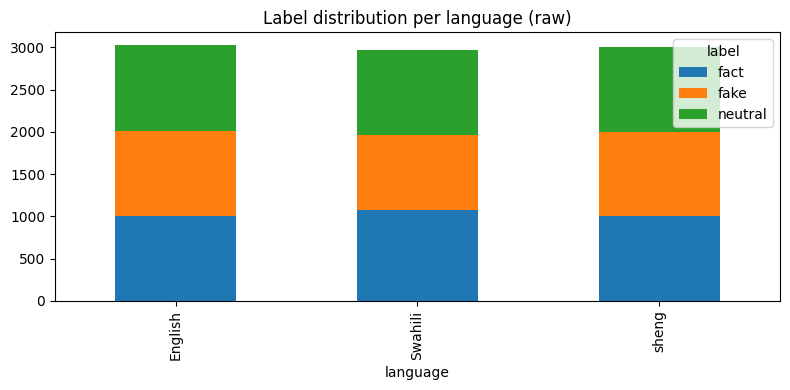

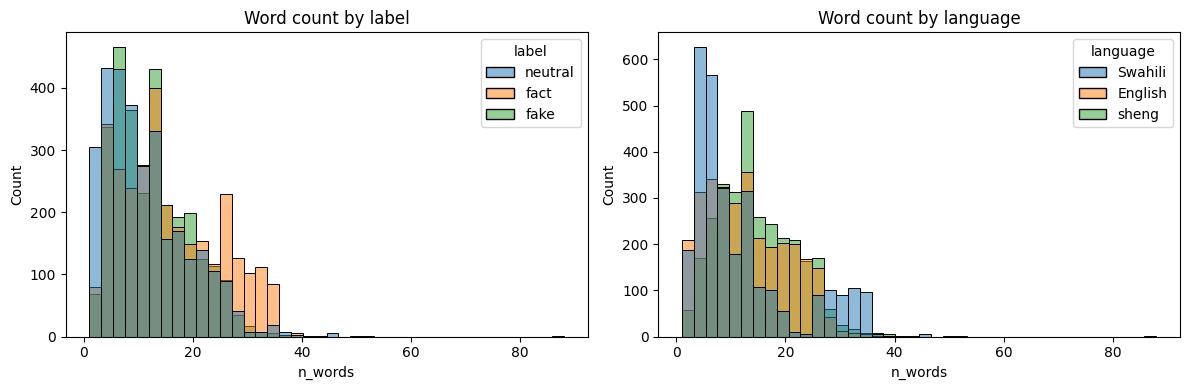

label            fact   fake  neutral
contains_emoji                       
False           0.878  0.915    0.702
True            0.122  0.085    0.298
language        English  Swahili  sheng
contains_emoji                         
False             0.604    0.996  0.896
True              0.396    0.004  0.104

Top tokens — neutral:
[('kenya', 1106), ('vote', 687), ('iebc', 596), ('elections', 464), ('na', 375), ('s', 321), ('ya', 282), ('ni', 266), ('decides', 206), ('baba', 193), ('polls', 188), ('t', 178), ('th', 154), ('wa', 153), ('kwa', 146), ('president', 143), ('ballot', 129), ('azimio', 118), ('people', 109), ('kura', 102)]

Top tokens — fact:
[('kenya', 1535), ('vote', 924), ('elections', 872), ('iebc', 854), ('ya', 814), ('kura', 579), ('wa', 536), ('vijana', 505), ('na', 406), ('za', 390), ('kwa', 357), ('s', 353), ('peace', 309), ('uchaguzi', 290), ('mkuu', 261), ('kazi', 233), ('ncic', 216), ('rekodi', 210), ('amani', 209), ('ni', 207)]

Top tokens — fake:
[('vote', 819),

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re

#Class x Language contingency
ct = pd.crosstab(df['language'], df['label'])
print("Class x Language:\n", ct, "\n")
ct.plot(kind='bar', stacked=True, figsize=(8,4))
plt.title("Label distribution per language (raw)")
plt.tight_layout(); plt.show()

#Text length
df['n_words'] = df['text'].fillna('').str.split().str.len()
df['n_chars'] = df['text'].fillna('').str.len()

fig, ax = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(data=df, x='n_words', hue='label', bins=40, ax=ax[0])
ax[0].set_title("Word count by label")
sns.histplot(data=df, x='n_words', hue='language', bins=40, ax=ax[1])
ax[1].set_title("Word count by language")
plt.tight_layout(); plt.show()

#Emoji by class / language
print(pd.crosstab(df['contains_emoji'], df['label'], normalize='columns').round(3))
print(pd.crosstab(df['contains_emoji'], df['language'], normalize='columns').round(3))

#Top tokens per class (after quick lowercase)
def top_tokens(series, n=20):
    c = Counter()
    for t in series.fillna('').str.lower():
        c.update(re.findall(r"[a-z']+", t))
    return c.most_common(n)

for lab in df['label'].unique():
    print(f"\nTop tokens — {lab}:")
    print(top_tokens(df.loc[df['label']==lab, 'text']))

#Duplicate count (raw)
print("\nExact duplicate tweets (raw):",
      df.duplicated(subset=['tweet']).sum())

**Cell 3:**  Data Cleaning takes place, where duplicates are removed, filling in missing values where needed, to improve perfomance of the model. Tokenizing of links, mentions, hashtags, emojis to standardize the data. Our scope is only text posts.

In [ ]:
import pandas as pd
import re
import numpy as np

#Load the dataset
#df = pd.read_csv("final_Dataset.csv")

#1. Drop the reduntant columns
df = df.drop(columns =['Unnamed: 0'])

#2. Reclean the raw 'tweet' column
def clean_tweet(text):
  if pd.isna(text):
    return ""

  #Lowercase
  text = text.lower()

  #Replace the URLs with a token
  text = re.sub(r'https?://\S+', ' url ', text)

  #Replace @mentions with a token
  text = re.sub(r'@\w+', ' user ', text)

  #Split CamelCase and keep the word
  def split_hashtag(match):
    tag = match.group(1)
    #insert space before capitals and between letters/digits
    tag = re.sub(r'([a-z])([A-Z])', r'\1 \2', tag)
    tag = re.sub(r'([A-zA-Z])(\d)', r'\1 \2', tag)
    return ' ' + tag.lower() + ' '
  text = re.sub(r'#(\w+)', split_hashtag, text)
  #Replace emojis with a token (Keeps signal without breaking tokenizer)
  text = re.sub(r'[\U0001F300-\U0001FAFF\U00002700-\U000027BF]', ' emoji ', text)
  #Replace newlines and multiple whitespace with space
  text = re.sub(r'\s+', ' ', text)
  #Remove lefover punctuation but keep apostrophes for contractions
  text = re.sub(r'[^\w\s\']', ' ', text)
  #Collapse again after punctuation removal
  text = re.sub(r'\s+', ' ', text).strip()
  return text

df['tweet_clean'] = df['tweet'].apply(clean_tweet)

#Sanity check: view a few examples
print("===Before===")
print(df['tweet'].iloc[3])
print("\n===After (tweet_clean) ===")
print(df['tweet_clean'].iloc[3])
print("\n=== Existing 'text' column ===")
print(df['text'].iloc[3])

#3. Remove exact duplicates (on the cleaned text + labels)
before = len(df)
df = df.drop_duplicates(subset=['tweet_clean', 'label'], keep='first').reset_index(drop=True)
after = len(df)
print(f"\n[De-dup] Removed {before - after} duplicates. Remaining: {after}")
#print(f"[De-dup] SKIPPED to preserve language balance. Keeping all {before} rows.")

#4. Removing otliers: drop empty or near-empty text
df = df[df['tweet_clean'].str.split().str.len() >= 3].reset_index(drop=True)
print(f"[Outlier removal] Remaining after dropping <3-word rows: {len(df)}")

#5. Drop Swahili data
before = len(df)
df = df[df['language'].str.lower() != 'swahili'].reset_index(drop=True)
print(f"Removed {before - len(df)} Swahili rows. Remaining: {len(df)}")
print(df['language'].value_counts())

#6. Check the class/language distribution AFTER cleaning.
print("\n[After cleaning] labels distribution:")
print(df['label'].value_counts())
print("\n[After cleaning] Language distribution:")
print(df['language'].value_counts())



===Before===
SakajaJohnson WilliamsRuto Hongera kabisa

===After (tweet_clean) ===
sakajajohnson williamsruto hongera kabisa

=== Existing 'text' column ===
sakajajohnson williamsruto hongera kabisa

[De-dup] Removed 2156 duplicates. Remaining: 6844
[Outlier removal] Remaining after dropping <3-word rows: 6841
Removed 816 Swahili rows. Remaining: 6025
language
English    3026
sheng      2999
Name: count, dtype: int64

[After cleaning] labels distribution:
label
neutral    2013
fact       2007
fake       2005
Name: count, dtype: int64

[After cleaning] Language distribution:
language
English    3026
sheng      2999
Name: count, dtype: int64


From the Output:

2,156 exact duplicates were removed (almost all Swahili) and 3 very short rows were dropped, leaving 6,841 rows. De-duplication was necessary, because keeping the copies would let the model memorise repeats and leak them across the train/test split.

The cost is that Swahili falls from 2,971 rows to 816, against about 3,000 each for English and Sheng. That is too little to train on or to test fairly (only about 143 test tweets), so the next cell removes Swahili and the project continues with English and Sheng only.

**Cell 4**
**Drop the Swahili data**: swahili text from the dataset was few, hence it was dropped, to help improve performance of the data. The dataset now contains English and Sheng text data only.


In [ ]:
before = len(df)
df = df[df['language'].str.lower() != 'swahili'].reset_index(drop=True)
print(f"[Drop Swahili] Removed {before - len(df)} rows. Remaining: {len(df)}")

print("\nLanguage distribution:")
print(df['language'].value_counts())
print("\nLabel distribution:")
print(df['label'].value_counts())
print("\nLabel x language:")
print(pd.crosstab(df['language'], df['label']))

[Drop Swahili] Removed 0 rows. Remaining: 6025

Language distribution:
language
English    3026
sheng      2999
Name: count, dtype: int64

Label distribution:
label
neutral    2013
fact       2007
fake       2005
Name: count, dtype: int64

Label x language:
label     fact  fake  neutral
language                     
English   1007  1005     1014
sheng     1000  1000      999


**Cell 5: Encode labels and split the data**

What this cell does:

1. Turns the labels into numbers: fact = 0, fake = 1, neutral = 2.
2. Builds a combined key of label and language, so every split keeps the same mix of English and Sheng in each class.
3. Splits off 20% for testing, then takes 12.5% of the remainder for validation. That gives roughly 70% training, 10% validation and 20% testing.
4. Prints the size and class balance of each split, and the language mix of the test set.

The random seed is fixed (42), so the split is the same every time and the baseline and the transformer are scored on exactly the same tweets. This replaces the earlier split code, which split the data twice and used only the second split.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Encode labels
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['label'])
print("Label mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

# Composite stratification key: label x language
df['strat_key'] = df['label'] + '__' + df['language']

x = df['tweet_clean']
y = df['label_encoded']

# 20% test
X_temp, X_test, y_temp, y_test, idx_temp, idx_test = train_test_split(
    x, y, df.index,
    test_size=0.20, random_state=42, stratify=df['strat_key']
)

# 12.5% of the remaining 80% for validation (= 10% overall)
X_train, X_val, y_train, y_val, idx_train, idx_val = train_test_split(
    X_temp, y_temp, idx_temp,
    test_size=0.125, random_state=42, stratify=df.loc[idx_temp, 'strat_key']
)

print(f"\nTrain: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print("\nTrain label distribution:\n", y_train.value_counts())
print("\nVal label distribution:\n", y_val.value_counts())
print("\nTest label distribution:\n", y_test.value_counts())
print("\nTest language mix:\n", df.loc[idx_test, 'language'].value_counts())

Label mapping: {'fact': np.int64(0), 'fake': np.int64(1), 'neutral': np.int64(2)}

Train: 4217 | Val: 603 | Test: 1205

Train label distribution:
 label_encoded
2    1409
0    1405
1    1403
Name: count, dtype: int64

Val label distribution:
 label_encoded
0    201
1    201
2    201
Name: count, dtype: int64

Test label distribution:
 label_encoded
2    403
0    401
1    401
Name: count, dtype: int64

Test language mix:
 language
English    605
sheng      600
Name: count, dtype: int64


**Cell 6: Baseline model, TF-IDF + Logistic Regression.**

A baseline is a simple model that sets the bar of which the advanced model must surpass.
Macro-F1 has been used to validate results of the model due to class imbalance in the dataset.



In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

#TF-IDF Baseline(Fit on train Only)
tfidf = TfidfVectorizer(
    max_features=8000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

x_train_tfidf = tfidf.fit_transform(X_train)
x_val_tfidf = tfidf.transform(X_val)
x_test_tfidf = tfidf.transform(X_test)

print(f"TF-IDF vocab size: {len(tfidf.vocabulary_)}")
print(f"Train matrix: {x_train_tfidf.shape}")

#Train baseline
lr = LogisticRegression(max_iter=2000, random_state=42, n_jobs=-1)
lr.fit(x_train_tfidf, y_train)

#Validation F1
val_pred = lr.predict(x_val_tfidf)
val_f1 = f1_score(y_val, val_pred, average='macro')
print(f"\n[Baseline LR] Validation F1 (macro): {val_f1:.4f}")
print(classification_report(y_val, val_pred, target_names=le.classes_))




TF-IDF vocab size: 8000
Train matrix: (4217, 8000)

[Baseline LR] Validation F1 (macro): 0.5323
              precision    recall  f1-score   support

        fact       0.58      0.57      0.57       201
        fake       0.51      0.54      0.53       201
     neutral       0.51      0.49      0.50       201

    accuracy                           0.53       603
   macro avg       0.53      0.53      0.53       603
weighted avg       0.53      0.53      0.53       603



From the Output:

Baseline TF-IDF + Logistic Regression: validation macro-F1 = 0.532 (accuracy 53%); test macro-F1 = 0.543.

**Cell 7: Set up AfriBERTa fine-tuning (settings and helper code)**

AfriBERTa (castorini/afriberta_large) is a transformer pre-trained on many African languages. Earlier runs on this model scored about 0.56 macro-F1 and its validation loss was lowest after epoch 2-3, so the settings below stop training early and average several runs.



In [ ]:
import gc, math, shutil
import numpy as np
import torch
from torch.utils.data import Dataset
from scipy.special import softmax
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback,
    DataCollatorWithPadding,
    set_seed,
)

MODEL_NAME = "castorini/afriberta_large"
SEEDS = [42, 123, 2024]
MAX_LEN = 64
WARMUP_RATIO = 0.1

HPARAMS = dict(
    learning_rate=2e-5,
    num_train_epochs=4,
    weight_decay=0.05,
    per_device_train_batch_size=16,
    gradient_accumulation_steps=2,
)

class MisinfoDataset(Dataset):
    def __init__(self, texts, labels, tokenizer):
        self.enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN)  # no padding here
        self.labels = [int(l) for l in labels]
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    return {"f1_macro": f1_score(labels, preds, average="macro"),
            "accuracy": float((preds == labels).mean())}

print("GPU available:", torch.cuda.is_available())

GPU available: True


**Cell 8: Train and evaluate one run**

`run_one(seed)` fine-tunes AfriBERTa once and returns its test results. The train/validation/test split is fixed, so only the training randomness changes between seeds.

What this function does:

1. Sets the random seed, loads the tokenizer and builds the three datasets.
2. Loads AfriBERTa with a fresh 3-way classification head (the warning about `classifier.*` weights being newly initialised is expected).
3. Trains with the settings in `HPARAMS`. After every epoch it scores the validation set, keeps the best epoch by macro-F1, and stops early if there is no improvement for 2 epochs.
4. Scores the held-out test set and records macro-F1, accuracy, and a separate macro-F1 for English and Sheng.
5. Returns the raw model scores (logits) as well, so the three seeds can be averaged later.
6. Deletes the saved checkpoints so Colab does not run out of disk space.

In [ ]:
test_lang = df.loc[idx_test, "language"].values
LANGS = ["English", "sheng"]

def run_one(seed, save_dir=None):
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)

    train_ds = MisinfoDataset(X_train, y_train, tok)
    val_ds   = MisinfoDataset(X_val,   y_val,   tok)
    test_ds  = MisinfoDataset(X_test,  y_test,  tok)

    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3)

    # warm-up expressed as a number of steps (works in every transformers version)
    steps_per_epoch = math.ceil(len(train_ds) / (HPARAMS["per_device_train_batch_size"] * HPARAMS["gradient_accumulation_steps"]))
    warmup_steps = int(WARMUP_RATIO * steps_per_epoch * HPARAMS["num_train_epochs"])

    out_dir = f"./runs/afriberta_s{seed}"
    args = TrainingArguments(
        output_dir=out_dir,
        per_device_eval_batch_size=64,
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        logging_steps=50,
        fp16=torch.cuda.is_available(),
        warmup_steps=warmup_steps,
        seed=seed,
        data_seed=seed,
        report_to="none",
        **HPARAMS,
    )
    trainer = Trainer(
        model=model, args=args,
        train_dataset=train_ds, eval_dataset=val_ds,
        data_collator=DataCollatorWithPadding(tok, pad_to_multiple_of=8 if torch.cuda.is_available() else None),
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    trainer.train()
        #********
    if save_dir:
        trainer.save_model(save_dir)   # best epoch, because load_best_model_at_end=True
        tok.save_pretrained(save_dir)

    val_f1 = max(h["eval_f1_macro"] for h in trainer.state.log_history if "eval_f1_macro" in h)
    logits = trainer.predict(test_ds).predictions
    preds = logits.argmax(-1)

    res = {
        "seed": seed,
        "best_val_f1": val_f1,
        "test_f1_macro": f1_score(y_test, preds, average="macro"),
        "test_accuracy": float((preds == y_test.values).mean()),
    }
    for lang in LANGS:
        m = test_lang == lang
        res[f"f1_{lang}"] = f1_score(y_test.values[m], preds[m], average="macro")

    del trainer, model
    gc.collect(); torch.cuda.empty_cache()
    shutil.rmtree(out_dir, ignore_errors=True)
    return res, logits

**Cell 9: Run the 3 seeds**

This trains AfriBERTa 3 times (once per seed) on the English + Sheng data. Expect about 3-5 minutes per run on a Colab GPU. Make sure the runtime is set to GPU first (Runtime > Change runtime type).

The results of each run are kept in `results` and the raw test scores in `logits_store`, so nothing has to be retrained to produce the tables in the next cells.

In [ ]:
results, logits_store = [], {}
for seed in SEEDS:
    print(f"\n===== AfriBERTa | seed {seed} =====")
    r, lg = run_one(seed)
    results.append(r)
    logits_store[seed] = lg
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})


===== AfriBERTa | seed 42 =====


config.json:   0%|          | 0.00/731 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/257 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 1.55MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

... (24 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'seed': 2024, 'best_val_f1': 0.5636, 'test_f1_macro': 0.5493, 'test_accuracy': 0.5494, 'f1_English': 0.5707, 'f1_sheng': 0.528}


**Cell 10: Final evaluation: the baseline, the 3 runs and their average**

In this final step, we put thr system to the test by comparing our advanced AI models against a simple, standard guessing method to see which one performs better. To make sure our results are fair and reliable, we average the scores from three different runs of our AI, similar to getting a consensus from a panel of three experts rather than relying on just one person's opinion. The cell then prints a clear, detailed scorecard showing exactly how well this combined expert system did at identifying factual, fake, and neutral posts across both English and Sheng.

In [ ]:
import pandas as pd
from sklearn.metrics import classification_report, f1_score

yt = y_test.values

# 1. Baseline on the same test set
base_pred = lr.predict(x_test_tfidf)
print("TF-IDF + LR baseline (test)")
print(f"  macro-F1 = {f1_score(yt, base_pred, average='macro'):.4f}")
for lang in LANGS:
    m = test_lang == lang
    print(f"  {lang:8s} F1 = {f1_score(yt[m], base_pred[m], average='macro'):.4f}  ({m.sum()} tweets)")

# 2. The three runs
res_df = pd.DataFrame(results)
print("\nAfriBERTa, 3 seeds:")
display(res_df.round(4))
cols = ["best_val_f1", "test_f1_macro", "test_accuracy"] + [f"f1_{l}" for l in LANGS]
print("Mean:\n", res_df[cols].mean().round(4).to_string())
print("\nStd:\n", res_df[cols].std().round(4).to_string())

# 3. Ensemble: average the class probabilities of the 3 seeds
ens_probs = np.mean([softmax(logits_store[s], axis=1) for s in SEEDS], axis=0)
ens_pred = ens_probs.argmax(1)
print(f"\nEnsemble of {len(SEEDS)} seeds: macro-F1 = {f1_score(yt, ens_pred, average='macro'):.4f}, "
      f"accuracy = {(ens_pred == yt).mean():.4f}")

# 4. Detailed reports
print("\n=== Ensemble: overall test report ===")
print(classification_report(yt, ens_pred, target_names=le.classes_, zero_division=0))
for lang in LANGS:
    m = test_lang == lang
    print(f"\n=== {lang} ({m.sum()} tweets) ===")
    print(f"F1 macro: {f1_score(yt[m], ens_pred[m], average='macro'):.4f}")
    print(classification_report(yt[m], ens_pred[m], target_names=le.classes_, zero_division=0))

TF-IDF + LR baseline (test)
  macro-F1 = 0.5432
  English  F1 = 0.5479  (605 tweets)
  sheng    F1 = 0.5389  (600 tweets)

AfriBERTa, 3 seeds:


,seed,best_val_f1,test_f1_macro,test_accuracy,f1_English,f1_sheng
0,42,0.5708,0.5612,0.5618,0.5632,0.5590
1,123,0.5704,0.5467,0.5469,0.5525,0.5403
2,2024,0.5636,0.5493,0.5494,0.5707,0.5280


Mean:
 best_val_f1      0.5683
test_f1_macro    0.5524
test_accuracy    0.5527
f1_English       0.5621
f1_sheng         0.5425

Std:
 best_val_f1      0.0041
test_f1_macro    0.0077
test_accuracy    0.0080
f1_English       0.0091
f1_sheng         0.0156

Ensemble of 3 seeds: macro-F1 = 0.5586, accuracy = 0.5585

=== Ensemble: overall test report ===
              precision    recall  f1-score   support

        fact       0.61      0.59      0.60       401
        fake       0.51      0.58      0.54       401
     neutral       0.56      0.50      0.53       403

    accuracy                           0.56      1205
   macro avg       0.56      0.56      0.56      1205
weighted avg       0.56      0.56      0.56      1205


=== English (605 tweets) ===
F1 macro: 0.5654
              precision    recall  f1-score   support

        fact       0.59      0.61      0.60       201
        fake       0.52      0.55      0.53       201
     neutral       0.59      0.54      0.56       203

  

**Cell 11: From the results:**

AfriBERTa averaged 0.552 ± 0.008 macro-F1 across 3 seeds; the 3-seed ensemble scored 0.559 (accuracy 56%) against 0.543 for the TF-IDF baseline.

The gap (about 1.5 points) is within the margin of error for a 1,205-tweet test set.

English (0.565) is slightly stronger than Sheng (0.551); the difference is within the seed-to-seed spread.
fact is the easiest class (F1 0.60); fake (0.54) and neutral (0.53) are harder, and neutral is weakest in Sheng (0.50).

Limitation: the labels appear to follow topic and political-camp wording more than verifiable truth, and a cross-validated TF-IDF model reaches only about 0.56, which caps what any model can score. Relabelling a sample of the data is the most likely way to raise accuracy.

In [ ]:
#Connect to mobile dev
import json, shutil
FINAL_DIR = "./afriberta_misinfo_final"
res, _ = run_one(42, save_dir=FINAL_DIR)
print(res)
json.dump(list(le.classes_), open(f"{FINAL_DIR}/labels.json", "w"))  # ["fact","fake","neutral"]
shutil.make_archive("afriberta_misinfo_final", "zip", FINAL_DIR)

Loading weights:   0%|          | 0/165 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: castorini/afriberta_large
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.weight     | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,F1 Macro,Accuracy
1,2.052977,0.960512,0.515760,0.517413
2,1.810767,0.950941,0.519748,0.524046
3,1.597140,0.967713,0.548765,0.550580
4,1.370650,1.006239,0.570848,0.572139


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'seed': 42, 'best_val_f1': 0.5708475694177918, 'test_f1_macro': 0.5612002154531962, 'test_accuracy': 0.5618257261410788, 'f1_English': 0.5632387163042258, 'f1_sheng': 0.5590114341334879}


'/content/afriberta_misinfo_final.zip'